# Vegetation Dynamics in Virginia from Landsat 8/9 (NDVI, EVI, LAI)

This notebook builds **8-day composites** of three vegetation indices from Landsat 8 and 9 Collection 2
Level-2 surface reflectance over the whole state of Virginia in Google Earth Engine:

| Index | Formula |
|---|---|
| **NDVI** | (NIR − Red) / (NIR + Red) |
| **EVI** | 2.5 × (NIR − Red) / (NIR + 6·Red − 7.5·Blue + 1) |
| **LAI** | 3.618 × EVI − 0.118 (empirical, Boegh et al. 2002) |

**Outputs:** statewide 8-day time series with data coverage, seasonal curves by land-cover class
(ESA WorldCover: forest, grassland, cropland, built-up), growing-season statistics, time series at sample sites,
and statewide summer NDVI/LAI maps with year-to-year change.

> Ported from the original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

Keep the `ee.Initialize(...)` line and the folder lines together in this one cell.
Results of the slow Earth Engine steps are saved to `outputs/veg_va/` as they are computed, so if the kernel
restarts, simply **Restart & Run All** again: finished work is loaded from disk instead of being recomputed.

In [5]:
import os, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
import matplotlib.patches as mpatches
import requests
from PIL import Image

In [6]:
import ee
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="add your GEE username")

## 2. Parameters

In [7]:
# Region of interest: the whole state of Virginia
roi = (ee.FeatureCollection("TIGER/2018/States")
         .filter(ee.Filter.eq("NAME", "Virginia"))
         .geometry())
ROI_NAME = "Virginia"

START, END     = "2022-01-01", "2024-01-01"   # same period as the original script
INTERVAL       = 8          # composite length (days)
MAX_CLOUD      = 60         # scene-level cloud filter (%); clouds are also masked per pixel
SCALE          = 500        # scale (m) for statewide statistics; 30 m over a whole state is very slow
MIN_COVERAGE   = 0.30       # minimum share of the state with clear data for a composite to be plotted
GROWING_MONTHS = list(range(5, 11))   # May–October, as in the original charts

# Land-cover classes from ESA WorldCover 2021 (10 m)
CLASSES = {10: "Tree cover", 30: "Grassland", 40: "Cropland", 50: "Built-up"}
CLASS_COLORS = {"Tree cover": "#1b7837", "Grassland": "#a6d96a", "Cropland": "#fdae61", "Built-up": "#d73027"}

# Sample sites (replace with your own points; these play the role of 'geometry2' in the original script)
SITES = {
    "Shenandoah NP forest":       (-78.45, 38.55),
    "Shenandoah Valley farmland": (-78.95, 38.60),
    "Eastern Shore cropland":     (-75.80, 37.65),
}

INDICES = ["ndvi", "evi", "lai"]
LABELS = {"ndvi": "NDVI", "evi": "EVI", "lai": "LAI (m²/m²)"}

## 3. Landsat preprocessing and 8-day composites

Compared with the original script, clouds, cloud shadows, cirrus, snow and saturated pixels are removed
per pixel using the `QA_PIXEL` and `QA_RADSAT` bands, so a looser scene-level cloud filter can be used and
more clear observations are kept. Each 8-day composite takes the maximum value of each index (as in the original).

In [8]:
def prepare(img):
    qa = img.select("QA_PIXEL")
    clear = qa.bitwiseAnd(0b111111).eq(0)            # fill, dilated cloud, cirrus, cloud, shadow, snow
    sr = (img.select("SR_B.*").multiply(2.75e-05).add(-0.2)
             .updateMask(clear).updateMask(img.select("QA_RADSAT").eq(0)))
    ndvi = sr.normalizedDifference(["SR_B5", "SR_B4"]).rename("ndvi")
    evi = sr.expression("2.5 * ((nir - red) / (nir + 6 * red - 7.5 * blue + 1))",
                        {"nir": sr.select("SR_B5"), "red": sr.select("SR_B4"), "blue": sr.select("SR_B2")}).rename("evi")
    evi = evi.updateMask(evi.gte(-1).And(evi.lte(1)))  # drop unstable values
    lai = evi.multiply(3.618).subtract(0.118).clamp(0, 8).rename("lai")
    return ee.Image.cat(ndvi, evi, lai).copyProperties(img, ["system:time_start"])

landsat = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
             .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
             .filterDate(START, END)
             .filterBounds(roi)
             .filter(ee.Filter.lt("CLOUD_COVER", MAX_CLOUD)))
index = landsat.map(prepare)
print("Landsat scenes:", landsat.size().getInfo())

landcover = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
land = landcover.neq(80)                              # exclude permanent water

window_starts = pd.date_range(START, END, freq=f"{INTERVAL}D", inclusive="left")

def composite(t):
    d0 = ee.Date(t)
    d1 = d0.advance(INTERVAL, "day")
    scenes = index.filterDate(d0, d1)
    img = scenes.max()
    return img.set({"system:time_start": d0.millis(), "n_bands": img.bandNames().size(),
                    "n_scenes": scenes.size()})

def composites_for(starts):
    ms = [int(t.timestamp() * 1000) for t in starts]
    return ee.ImageCollection(ee.List(ms).map(lambda t: composite(t))).filter(ee.Filter.gt("n_bands", 0))

Landsat scenes: 873


## 4. Statewide and land-cover statistics for every composite

For each 8-day composite: the share of Virginia with clear data (`coverage`), the statewide mean of each
index, and the mean per land-cover class.

A whole state of Landsat data is a lot of computation, so composites are processed in small batches (`BATCH`);
a batch that exceeds Earth Engine's memory limit is retried one composite at a time. **Progress is saved after
every batch**, so an interrupted run resumes where it stopped. Set `FORCE_RECOMPUTE = True` to start over
(for example after changing parameters).

In [13]:
BATCH = 4                 # composites per request; lower it if memory errors persist
FORCE_RECOMPUTE = False   # True = ignore saved results and recompute everything

STATE_CSV = f"{OUT_DIR}/statewide_8day.csv"
CLASS_CSV = f"{OUT_DIR}/landcover_8day.csv"
DONE_CSV  = f"{OUT_DIR}/processed_windows.csv"

reduce_kw = dict(geometry=roi, scale=SCALE, maxPixels=1e13, tileScale=16)

def window_stats(img):
    clear = img.select("ndvi").mask().rename("coverage").updateMask(land)
    masked = img.updateMask(land)
    overall = masked.addBands(clear).reduceRegion(ee.Reducer.mean(), **reduce_kw)
    groups = masked.addBands(landcover).reduceRegion(
        ee.Reducer.mean().repeat(3).group(groupField=3, groupName="class"), **reduce_kw).get("groups")
    return ee.Feature(None, {"date": ee.Date(img.get("system:time_start")).format("YYYY-MM-dd"),
                             "n_scenes": img.get("n_scenes"), "coverage": overall.get("coverage"),
                             "ndvi": overall.get("ndvi"), "evi": overall.get("evi"), "lai": overall.get("lai"),
                             "groups": groups})

def fetch_safely(starts):
    """Return (features, windows processed). Splits the batch if Earth Engine runs out of memory."""
    try:
        feats = ee.FeatureCollection(composites_for(starts).map(window_stats)).getInfo()["features"]
        return feats, [f"{t:%Y-%m-%d}" for t in starts]
    except ee.EEException as e:
        if len(starts) == 1:
            print(f"  skipped {starts[0]:%Y-%m-%d} (will retry on next run): {e}")
            return [], []
        print(f"  batch from {starts[0]:%Y-%m-%d} too large, retrying one composite at a time")
        feats, done = [], []
        for t in starts:
            f, d = fetch_safely(pd.DatetimeIndex([t]))
            feats += f; done += d
        return feats, done

def load_saved(path, columns):
    if os.path.exists(path) and not FORCE_RECOMPUTE:
        return pd.read_csv(path)
    return pd.DataFrame(columns=columns)

state_df = load_saved(STATE_CSV, ["date", "n_scenes", "coverage", *INDICES])
class_df = load_saved(CLASS_CSV, ["date", "class", *INDICES])
done = set(load_saved(DONE_CSV, ["window"])["window"])

todo = pd.DatetimeIndex([t for t in window_starts if f"{t:%Y-%m-%d}" not in done])
print(f"{len(window_starts) - len(todo)} windows already done, {len(todo)} to process")

for i in range(0, len(todo), BATCH):
    feats, finished = fetch_safely(todo[i:i + BATCH])
    new_state, new_class = [], []
    for f in feats:
        p = f["properties"]
        new_state.append({k: p.get(k) for k in ["date", "n_scenes", "coverage", *INDICES]})
        for g in p.get("groups") or []:
            if g["class"] in CLASSES:
                new_class.append({"date": p["date"], "class": CLASSES[g["class"]], **dict(zip(INDICES, g["mean"]))})
    state_df = pd.concat([state_df, pd.DataFrame(new_state)], ignore_index=True)
    class_df = pd.concat([class_df, pd.DataFrame(new_class)], ignore_index=True)
    done.update(finished)
    state_df.to_csv(STATE_CSV, index=False)                       # save progress after every batch
    class_df.to_csv(CLASS_CSV, index=False)
    pd.DataFrame({"window": sorted(done)}).to_csv(DONE_CSV, index=False)
    print(f"{min(i + BATCH, len(todo))}/{len(todo)} windows processed")

state = (state_df.assign(date=lambda d: pd.to_datetime(d["date"]))
                 .drop_duplicates("date", keep="last").set_index("date").sort_index()
                 .astype({c: float for c in ["coverage", *INDICES]}))
by_class = (class_df.assign(date=lambda d: pd.to_datetime(d["date"]))
                    .drop_duplicates(["date", "class"], keep="last")
                    .astype({c: float for c in INDICES})
                    .merge(state[["coverage"]], left_on="date", right_index=True))
print(f"Composites available: {len(state)}")
state.round(3).head()

0 windows already done, 92 to process


C:\Users\moham\AppData\Local\Temp\ipykernel_77372\1603280670.py:58: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  state_df = pd.concat([state_df, pd.DataFrame(new_state)], ignore_index=True)
C:\Users\moham\AppData\Local\Temp\ipykernel_77372\1603280670.py:59: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  class_df = pd.concat([class_df, pd.DataFrame(new_class)], ignore_index=True)


4/92 windows processed
8/92 windows processed
12/92 windows processed
16/92 windows processed
20/92 windows processed
24/92 windows processed
28/92 windows processed
32/92 windows processed
36/92 windows processed
40/92 windows processed
44/92 windows processed
48/92 windows processed
52/92 windows processed
56/92 windows processed
60/92 windows processed
64/92 windows processed
68/92 windows processed
72/92 windows processed
76/92 windows processed
80/92 windows processed
84/92 windows processed
88/92 windows processed
92/92 windows processed
Composites available: 92


,n_scenes,coverage,ndvi,evi,lai
date,,,,,
2022-01-01,10,0.347,0.530,0.251,0.790
2022-01-09,4,0.048,0.470,0.229,0.713
2022-01-17,11,0.448,0.469,0.243,0.763
2022-01-25,7,0.287,0.491,0.250,0.788
2022-02-02,10,0.791,0.501,0.236,0.735


In [14]:
FIG_DIR, OUT_DIR = "figures/veg_va", "outputs/veg_va"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

In [15]:
state = (pd.read_csv(f"{OUT_DIR}/statewide_8day.csv", parse_dates=["date"])
           .drop_duplicates("date", keep="last").set_index("date").sort_index())
by_class = (pd.read_csv(f"{OUT_DIR}/landcover_8day.csv", parse_dates=["date"])
              .drop_duplicates(["date", "class"], keep="last")
              .merge(state[["coverage"]], left_on="date", right_index=True))
print(len(state), "composites loaded")

92 composites loaded


## 5. Growing-season statistics

In [16]:
good = state[state["coverage"] >= MIN_COVERAGE]
good_cls = by_class[by_class["coverage"] >= MIN_COVERAGE]
print(f"Composites with ≥{MIN_COVERAGE:.0%} clear coverage: {len(good)} of {len(state)}")

def season_summary(df):
    gs = df[df.index.month.isin(GROWING_MONTHS)] if isinstance(df.index, pd.DatetimeIndex) else df
    out = {}
    for col in INDICES:
        out[f"{LABELS[col]} mean (May–Oct)"] = gs[col].mean()
        out[f"{LABELS[col]} peak"] = gs[col].max()
    out["Peak NDVI date"] = gs["ndvi"].idxmax().strftime("%Y-%m-%d") if len(gs) else None
    out["Composites used"] = len(gs)
    return pd.Series(out)

statewide_summary = pd.DataFrame({str(y): season_summary(g) for y, g in good.groupby(good.index.year)})
statewide_summary.to_csv(f"{OUT_DIR}/statewide_growing_season_summary.csv")

gs_cls = good_cls[good_cls["date"].dt.month.isin(GROWING_MONTHS)]
class_summary = (gs_cls.assign(year=gs_cls["date"].dt.year)
                   .groupby(["class", "year"])[INDICES].agg(["mean", "max"]).round(3))
class_summary.to_csv(f"{OUT_DIR}/landcover_growing_season_summary.csv")
display(statewide_summary)
class_summary

Composites with ≥30% clear coverage: 74 of 92


,2022,2023
NDVI mean (May–Oct),0.777542,0.783496
NDVI peak,0.837784,0.8234
EVI mean (May–Oct),0.534352,0.535442
EVI peak,0.616603,0.615898
LAI (m²/m²) mean (May–Oct),1.815442,1.819402
LAI (m²/m²) peak,2.113086,2.110321
Peak NDVI date,2022-08-05,2023-07-23
Composites used,20,21


ndvi           evi           lai       
                  mean    max   mean    max   mean    max
class      year                                          
Built-up   2022  0.513  0.556  0.338  0.379  1.104  1.253
           2023  0.517  0.575  0.339  0.401  1.108  1.334
Cropland   2022  0.684  0.830  0.490  0.664  1.655  2.286
           2023  0.683  0.813  0.486  0.637  1.640  2.186
Grassland  2022  0.750  0.811  0.537  0.622  1.827  2.132
           2023  0.748  0.791  0.526  0.595  1.785  2.035
Tree cover 2022  0.799  0.852  0.544  0.638  1.850  2.192
           2023  0.805  0.842  0.547  0.637  1.860  2.186

## 6. Figures

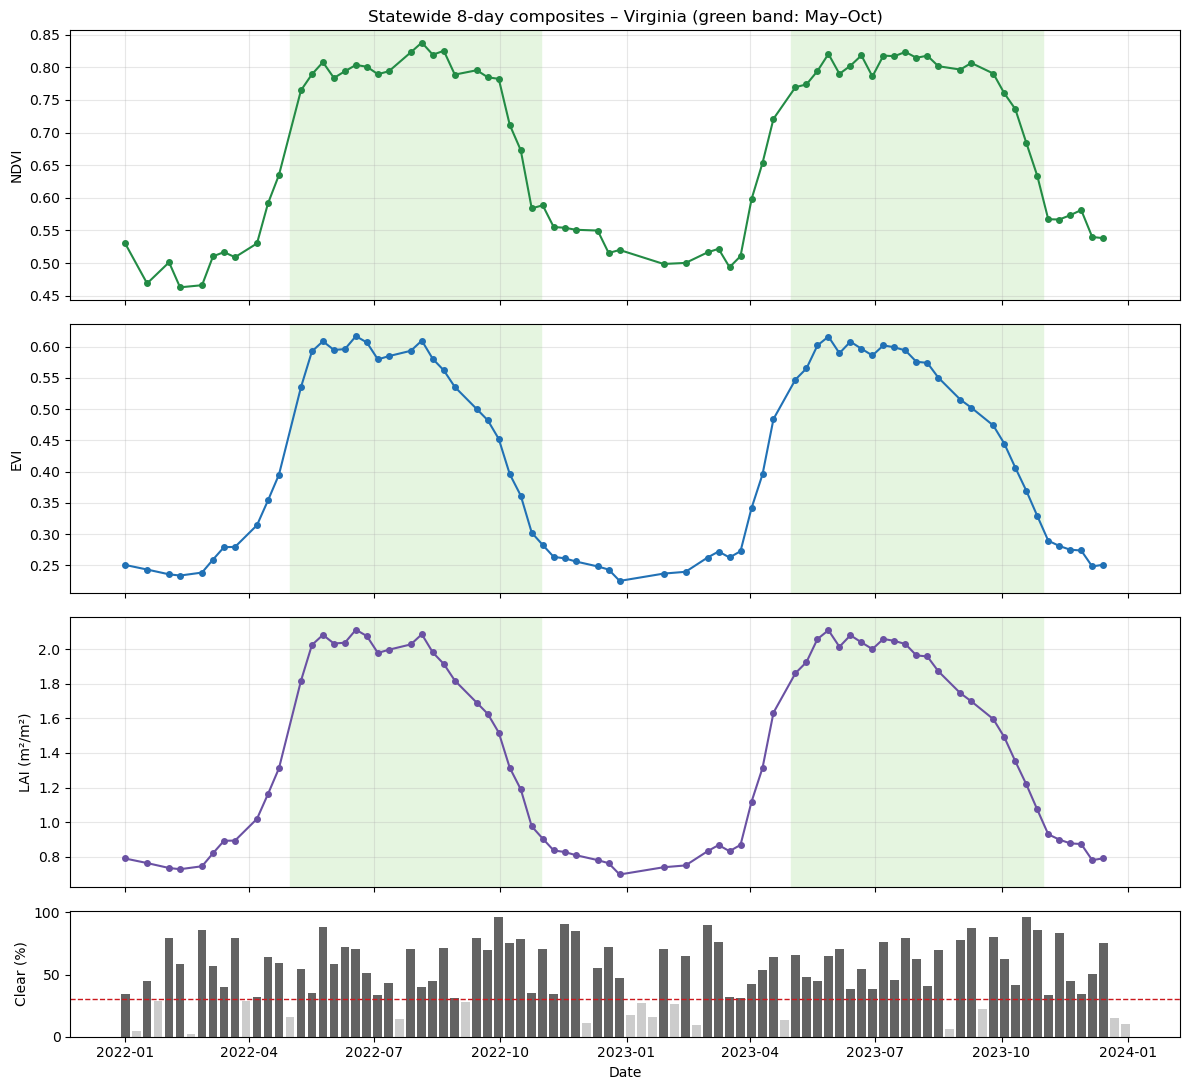

In [17]:
def shade_growing(ax):
    for y in sorted(set(state.index.year)):
        ax.axvspan(pd.Timestamp(y, GROWING_MONTHS[0], 1),
                   pd.Timestamp(y, GROWING_MONTHS[-1], 1) + pd.offsets.MonthEnd(1),
                   color="#e5f5e0", zorder=0)

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True,
                         gridspec_kw={"height_ratios": [3, 3, 3, 1.4]})
for ax, col, color in zip(axes, INDICES, ["#238b45", "#2171b5", "#6a51a3"]):
    shade_growing(ax)
    ax.plot(good.index, good[col], "o-", color=color, ms=4)
    ax.set_ylabel(LABELS[col]); ax.grid(alpha=0.3)
axes[0].set_title(f"Statewide 8-day composites – {ROI_NAME} (green band: May–Oct)")
axes[3].bar(state.index, 100 * state["coverage"], width=INTERVAL * 0.8,
            color=np.where(state["coverage"] >= MIN_COVERAGE, "#636363", "#cccccc"))
axes[3].axhline(100 * MIN_COVERAGE, color="#cb181d", ls="--", lw=1)
axes[3].set(ylabel="Clear (%)", xlabel="Date")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_statewide_timeseries.png"); plt.show()

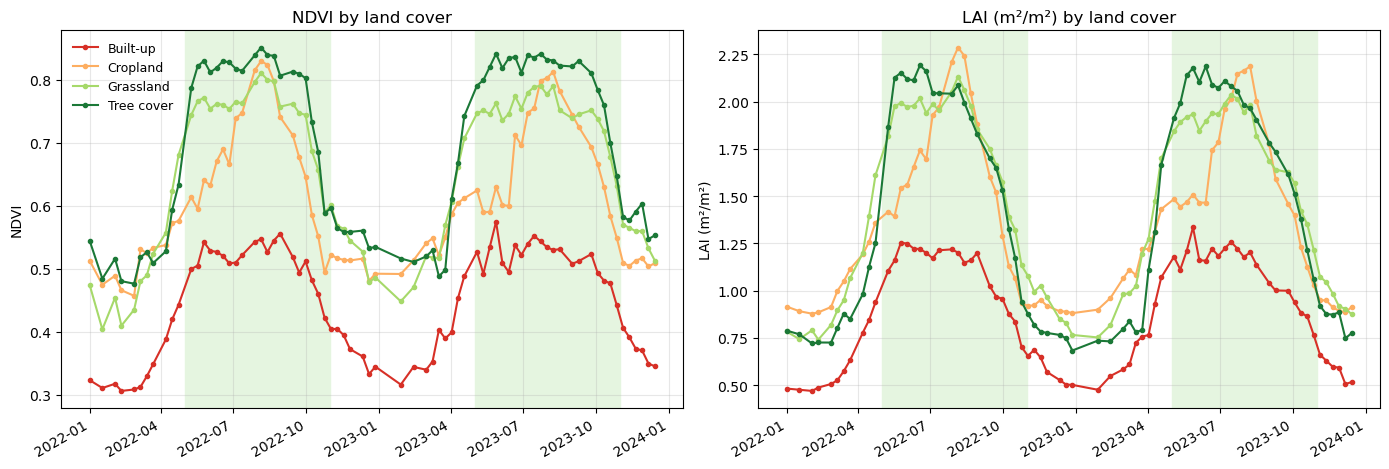

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True)
for ax, col in zip(axes, ["ndvi", "lai"]):
    shade_growing(ax)
    for name, g in good_cls.groupby("class"):
        ax.plot(g["date"], g[col], "o-", ms=3, color=CLASS_COLORS[name], label=name)
    ax.set(ylabel=LABELS[col], title=f"{LABELS[col]} by land cover"); ax.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=9)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_landcover_timeseries.png"); plt.show()

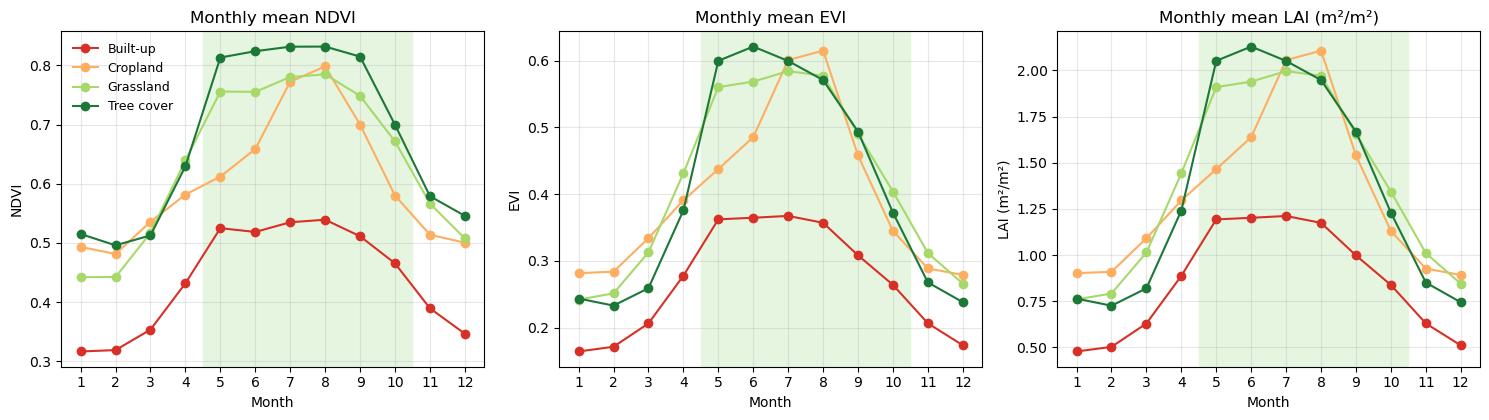

In [19]:
# Average seasonal cycle by land cover (day of year, all years pooled)
clim = (good_cls.assign(month=good_cls["date"].dt.month)
                .groupby(["class", "month"])[INDICES].mean().reset_index())
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharex=True)
for ax, col in zip(axes, INDICES):
    ax.axvspan(GROWING_MONTHS[0] - 0.5, GROWING_MONTHS[-1] + 0.5, color="#e5f5e0", zorder=0)
    for name, g in clim.groupby("class"):
        ax.plot(g["month"], g[col], "o-", color=CLASS_COLORS[name], label=name)
    ax.set(xticks=range(1, 13), xlabel="Month", ylabel=LABELS[col], title=f"Monthly mean {LABELS[col]}")
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_seasonal_cycle_by_landcover.png"); plt.show()

### Sample sites

Equivalent to the original `ui.Chart.image.series` charts for `geometry2`, extended to several sites.
Values are the 30 m pixel at each point in every 8-day composite.

In [21]:
SITES_CSV = f"{OUT_DIR}/sites_8day.csv"

if os.path.exists(SITES_CSV) and not FORCE_RECOMPUTE:
    sites = pd.read_csv(SITES_CSV, parse_dates=["date"])
    print("Loaded saved site values")
else:
# Extract every clear Landsat observation at each point (light request: one pixel per scene),
# then build the 8-day maximum composites locally, exactly as in Earth Engine.
    frames = []
    for name, (lon_pt, lat_pt) in SITES.items():
        pt = ee.Geometry.Point([lon_pt, lat_pt])
        region = index.filterBounds(pt).getRegion(pt, 30).getInfo()
        obs = pd.DataFrame(region[1:], columns=region[0])
        obs = obs.dropna(subset=["ndvi"]).assign(site=name)
        obs["obs_date"] = pd.to_datetime(obs["time"], unit="ms")
        frames.append(obs)
        print(f"{name}: {len(obs)} clear observations")

    raw = pd.concat(frames, ignore_index=True)
    start_ts = pd.Timestamp(START)
    raw["date"] = start_ts + pd.to_timedelta((raw["obs_date"] - start_ts).dt.days // INTERVAL * INTERVAL, unit="D")
    sites = (raw.groupby(["site", "date"])[INDICES].max().reset_index().sort_values("date"))
    sites.round(4).to_csv(SITES_CSV, index=False)

Shenandoah NP forest: 37 clear observations
Shenandoah Valley farmland: 40 clear observations
Eastern Shore cropland: 47 clear observations


## 7. Statewide summer maps

Summer (June–August) median of all clear Landsat observations at 30 m, for each year, plus the change between
the first and last year. Maps are rendered as static images (`getThumbURL`) so they display on GitHub.

  ndvi_2022: 1400px
  ndvi_2023: 1400px
  ndvi_change_2022_2023: 1400px
  lai_2023: 1400px


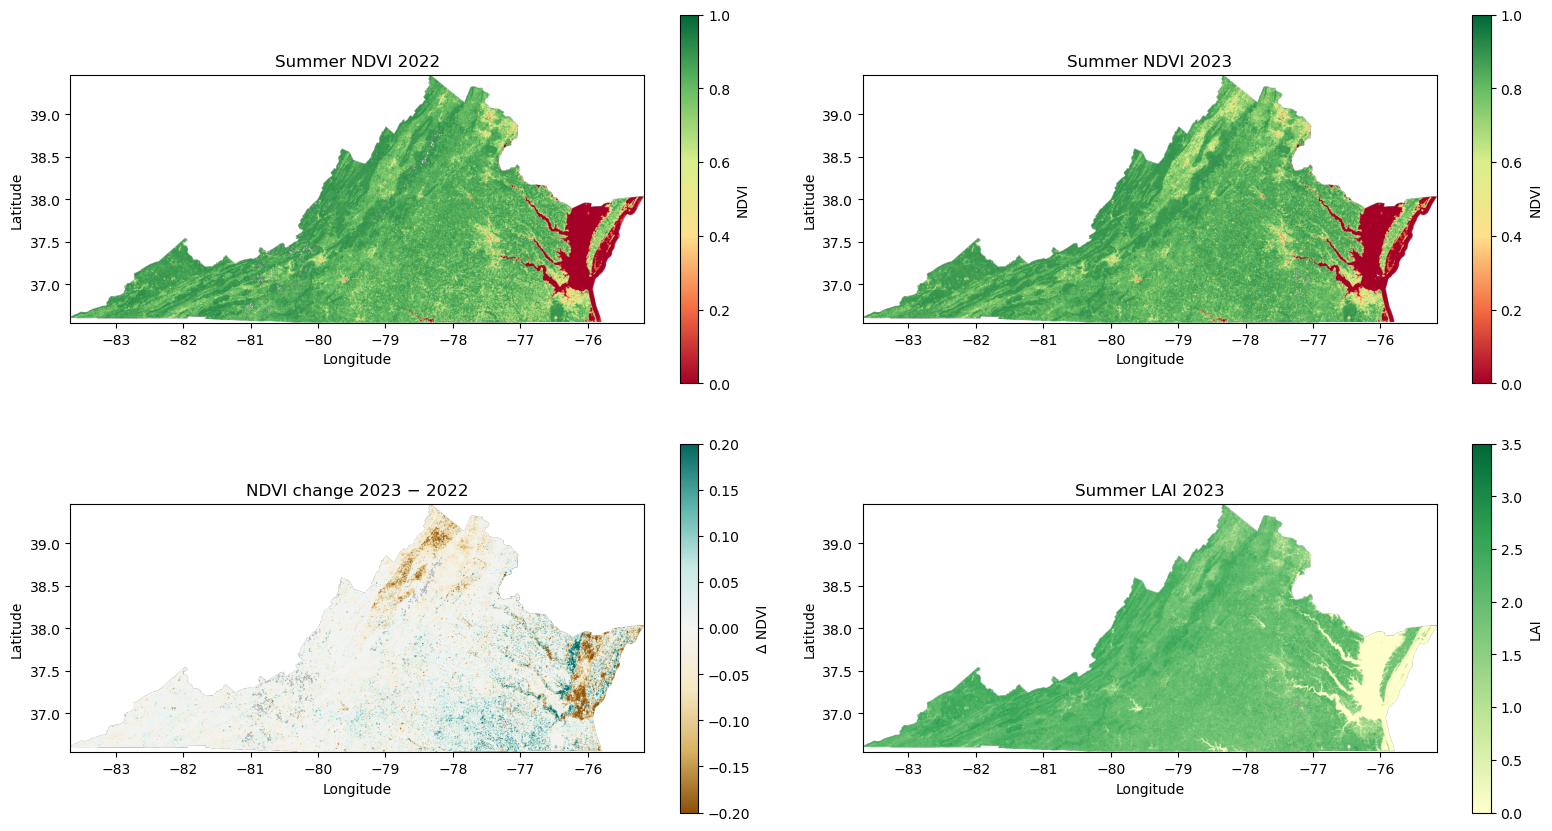

In [22]:
years = sorted(set(window_starts.year))
def summer(year):
    return index.filter(ee.Filter.calendarRange(year, year, "year")).filter(ee.Filter.calendarRange(6, 8, "month")).median()

NDVI_PAL = ["#a50026", "#f46d43", "#fee08b", "#d9ef8b", "#66bd63", "#006837"]
DIFF_PAL = ["#8c510a", "#d8b365", "#f6e8c3", "#f5f5f5", "#c7eae5", "#5ab4ac", "#01665e"]
LAI_PAL  = ["#ffffcc", "#c2e699", "#78c679", "#31a354", "#006837"]

MAP_DIR = f"{OUT_DIR}/map_images"
os.makedirs(MAP_DIR, exist_ok=True)

def thumb(key, image, band, vmin, vmax, palette):
    """Render a statewide map once and save it; later runs load the saved image."""
    path = f"{MAP_DIR}/{key}.png"
    if os.path.exists(path) and not FORCE_RECOMPUTE:
        return np.array(Image.open(path))
    vis = image.select(band).visualize(min=vmin, max=vmax, palette=palette).clip(roi)
    for dims in (1400, 1000, 700):          # smaller image if Earth Engine runs out of memory/time
        try:
            url = vis.getThumbURL({"region": roi.bounds(), "dimensions": dims, "crs": "EPSG:4326", "format": "png"})
            resp = requests.get(url, timeout=600)
            resp.raise_for_status()
            img = Image.open(io.BytesIO(resp.content))
            img.save(path)
            print(f"  {key}: {dims}px")
            return np.array(img)
        except Exception as e:
            print(f"  {key} at {dims}px failed ({str(e)[:80]}), trying smaller")
    raise RuntimeError(f"Could not render map {key}")

b = np.array(roi.bounds().coordinates().getInfo()[0])
extent = [b[:, 0].min(), b[:, 0].max(), b[:, 1].min(), b[:, 1].max()]

panels = [(thumb(f"ndvi_{y}", summer(y), "ndvi", 0, 1, NDVI_PAL), NDVI_PAL, 0, 1, f"Summer NDVI {y}", "NDVI") for y in years]
if len(years) > 1:
    diff = summer(years[-1]).subtract(summer(years[0]))
    panels.append((thumb(f"ndvi_change_{years[0]}_{years[-1]}", diff, "ndvi", -0.2, 0.2, DIFF_PAL), DIFF_PAL, -0.2, 0.2,
                   f"NDVI change {years[-1]} − {years[0]}", "Δ NDVI"))
panels.append((thumb(f"lai_{years[-1]}", summer(years[-1]), "lai", 0, 3.5, LAI_PAL), LAI_PAL, 0, 3.5, f"Summer LAI {years[-1]}", "LAI"))

ncol = 2
nrow = int(np.ceil(len(panels) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 4.6 * nrow))
for ax, (arr, pal, lo, hi, title, unit) in zip(np.ravel(axes), panels):
    ax.imshow(arr, extent=extent)
    sm = plt.cm.ScalarMappable(cmap=LinearSegmentedColormap.from_list("p", pal), norm=Normalize(lo, hi))
    fig.colorbar(sm, ax=ax, label=unit, shrink=0.8)
    ax.set_title(title); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_aspect(1 / np.cos(np.deg2rad(37.5)))
for ax in np.ravel(axes)[len(panels):]:
    ax.axis("off")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/05_summer_maps.png"); plt.show()

## 8. Notes

- **Data:** USGS Landsat 8/9 Collection 2 Level-2 surface reflectance (scale 2.75e-05, offset −0.2);
  ESA WorldCover 2021 v200 (Zanaga et al. 2022).
- **LAI** uses the empirical EVI relation of Boegh et al. (2002), developed for agricultural fields; for forests it is
  an approximation and is best read as a relative index.
- An 8-day window of Landsat 8 + 9 covers each location about once, and clouds remove more, so statewide composites
  are always partial. The `coverage` column (and grey bars in Figure 1) shows how much of the state each composite
  represents; composites below `MIN_COVERAGE` are left out of the plots and statistics. A longer `INTERVAL`
  (e.g. 16 days) gives fuller coverage.
- Statewide and land-cover means are computed at `SCALE` = 500 m for speed; site values and maps use 30 m.
- Intermediate results are saved in `outputs/veg_va/` (CSV tables and rendered map images), so re-running the
  notebook is fast. Set `FORCE_RECOMPUTE = True` in Section 4 after changing parameters.
- To analyse more years, change `END` (Landsat 9 data start in late 2021). If a request times out,
  increase `SCALE` or `INTERVAL`.